# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Maribao, Jake Agustin
- _Student No._: 2023-08777
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

![Figure 1](interp_sine.png)

**Figure 1. Synthetic data interpolation.** Ten points drawn at random from $\sin x$ on
$[0, 2\pi]$ (red) are reconstructed by nearest, linear, quadratic and cubic interpolation (blue)
and compared with the true function (dashed). The samples only span $[0.59, 6.13]$, so the grey
bands mark where each curve is extrapolated (dotted) instead of interpolated. Inside the sampled
domain the RMSE falls from 0.280 (nearest) and 0.191 (linear) to 0.017 for both quadratic and
cubic. Outside it every curve departs from $\sin x$, and the quadratic and cubic curves leave the
range $[-1, 1]$ that a sine never exceeds.

![Figure 2](interp_dow.png)

**Figure 2. Real-world data reconstruction.** The 1024-day Dow Jones closing series (grey)
rebuilt by linear interpolation (blue) from random subsets of 50%, 30%, 10% and 5% of the days
(red). The subsets are nested, so the 5% sample is part of the 10% sample, and so on. The
held-out RMSE, measured only on the days that were left out, is 168, 170, 232 and 387 points.
At 5% no sample falls on the March 2009 low, so the reconstruction never goes below 7,776 while
the true minimum is 6,547 on day 572.

### Report discussion

**Interpolator comparison:** For the smooth sine, accuracy rises with the order of the
interpolant. Nearest holds flat values between samples (RMSE 0.280), linear follows straight
chords that cut inside every curved stretch (0.191), and the quadratic and cubic splines bend
with the function, cutting the error tenfold to 0.017. Higher order wins because the sine has
smooth derivatives that a low-degree polynomial piece can match. The ranking reverses on the
Dow data (Problem 3). At 10% sampling the held-out error is 232 for linear but 343 for quadratic
and 354 for cubic, and the cubic curve swings 659 points past the samples on either side of a
gap. A stock index changes direction from day to day, so there is no smooth trend for a
polynomial to follow and the extra curvature only adds false swings. Linear interpolation
cannot overshoot, which makes it the safer choice for rough data.

**Sampling-level comparison:** Fewer samples mean longer gaps, and the error grows with
them: 168, 170, 232 and 387 points at 50%, 30%, 10% and 5%. This follows a random walk,
where the uncertainty inside a gap of $g$ days scales like $\sqrt{g}$. With the measured daily
volatility of 154 points it predicts 141, 179, 280 and 402. At 50% and 30% most gaps
last a few days, so the error stays near that volatility. At 5% the reconstruction draws
straight lines across gaps of up to 104 days and misses the March 2009 low by 1,289 points,
because a linear interpolant cannot go below its lowest sample. Outside the sampled domain
nothing is rebuilt. The 5% sample loses 2 days at the start and 9 at the end.
Extrapolating there is unreliable: the quadratic fit to the sine already reaches 3.35 at
$x_{\max} + 2$, though a sine never exceeds 1.

### Other comments
- The rankings are not an accident of the random draw. Across 50 different seeds, quadratic
  and cubic beat linear, which beats nearest, on the sine every time. Linear had the lowest
  held-out error on the Dow in all 200 seed and sampling-level combinations, and the error grew
  as samples were removed in every seed.
- All sampling levels reuse one random permutation, so the subsets are nested and the levels
  differ only in the amount of data. The 10% sample happens to contain day 572, which is why
  only the 5% panel misses the March 2009 low.
- The series minimum, 6,547.05 on day 572, matches the Dow Jones closing low of 9 March 2009,
  which places the steep fall around days 460 to 570 in the 2008 financial crisis.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path
import urllib.request

SEED = 42
rng = np.random.default_rng(SEED)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

**Problem 1 notes**

- Ten points are drawn uniformly at random on $[0, 2\pi]$ and sorted, because `interp1d` needs
  increasing $x$. Each problem cell creates a fresh generator from the same seed, so re-running
  a cell always gives the same samples.
- `interp1d` builds four interpolants from the same samples: `nearest` (a step function),
  `linear` (straight segments), and `quadratic` and `cubic` (splines of degree 2 and 3 that
  join smoothly at the samples).
- Accuracy is the RMSE against $\sin x$ on a dense grid inside the sampled domain
  $[x_{\min}, x_{\max}]$. The random samples do not reach $0$ or $2\pi$, so the figure shades
  the region outside that domain and draws the extrapolated curves there as dotted lines,
  only to show how unreliable they are.

sampled domain [0.592, 6.130] of [0, 6.283], largest gap 1.953
    method  RMSE inside   extrapolated at x_min-1, x_max+1, x_max+2
      true                [-0.397  0.749  0.962]
   nearest       0.2796   [ 0.558 -0.153 -0.153]
    linear       0.1914   [-0.207  0.695  1.543]
 quadratic       0.0174   [-0.762  1.268  3.349]
     cubic       0.0173   [-0.83   0.934  1.774]


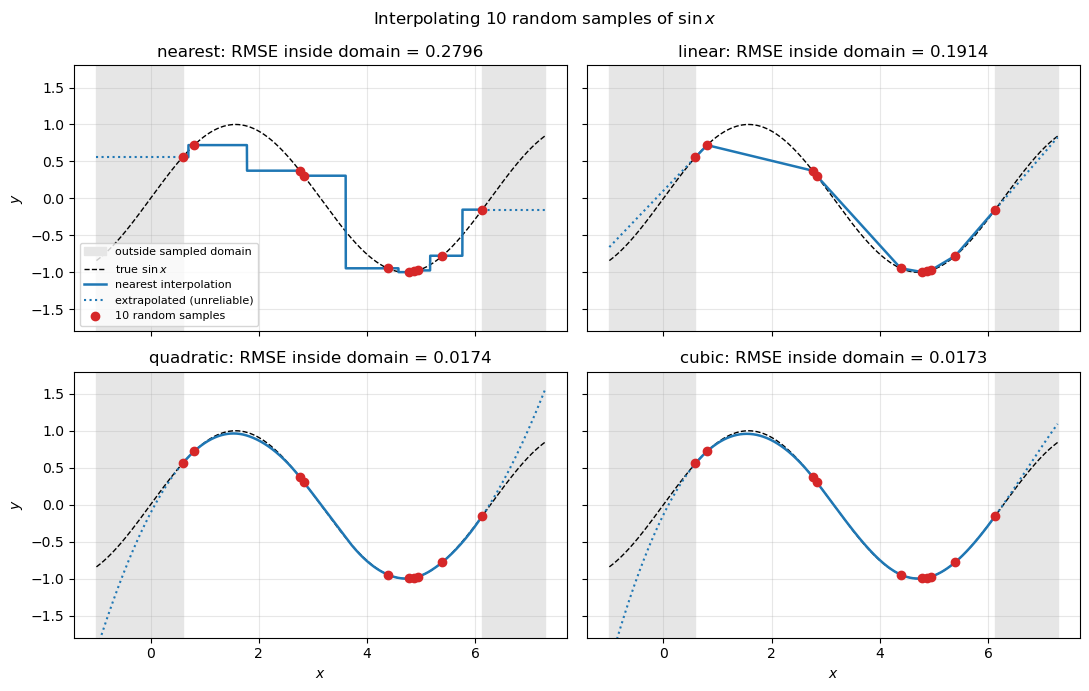

In [9]:
def true_fn(x):
    """The known function being sampled."""
    return np.sin(x)


N_SAMPLES = 10        # as the sample size increase the accuracy of every method will also increase, thus 10 samples is chosenso that the difference is large eough to see.  
METHODS = ('nearest', 'linear', 'quadratic', 'cubic')

rng = np.random.default_rng(SEED)              # fresh generator: same samples on every run
x_s = np.sort(rng.uniform(0, 2*np.pi, N_SAMPLES))
y_s = true_fn(x_s)

# Interpolants are built once and reused for the error table and the figure.
# fill_value='extrapolate' is used only to draw the shaded outside region.
interpolants = {k: interpolate.interp1d(x_s, y_s, kind=k, fill_value='extrapolate')
                for k in METHODS}

x_in = np.linspace(x_s[0], x_s[-1], 2001)     # inside the sampled domain
x_out = np.array([x_s[0] - 1, x_s[-1] + 1, x_s[-1] + 2])
print(f"sampled domain [{x_s[0]:.3f}, {x_s[-1]:.3f}] of [0, {2*np.pi:.3f}], largest gap {np.diff(x_s).max():.3f}")
print(f"{'method':>10s} {'RMSE inside':>12s}   extrapolated at x_min-1, x_max+1, x_max+2")
print(f"{'true':>10s} {'':>12s}   {np.round(true_fn(x_out), 3)}")
for k, f in interpolants.items():
    rmse = np.sqrt(np.mean((f(x_in) - true_fn(x_in))**2))
    print(f"{k:>10s} {rmse:12.4f}   {np.round(f(x_out), 3)}")

# REPORT FIGURE 1: samples, true function and the four interpolants
x_plot = np.linspace(-1, 2*np.pi + 1, 3001)
inside = (x_plot >= x_s[0]) & (x_plot <= x_s[-1])
fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (k, f) in zip(axs.flat, interpolants.items()):
    rmse = np.sqrt(np.mean((f(x_in) - true_fn(x_in))**2))
    ax.axvspan(x_plot[0], x_s[0], color='0.9')
    ax.axvspan(x_s[-1], x_plot[-1], color='0.9', label='outside sampled domain')
    ax.plot(x_plot, true_fn(x_plot), 'k--', lw=1, label=r'true $\sin x$')
    ax.plot(x_plot[inside], f(x_plot[inside]), color='C0', lw=1.8, label=f'{k} interpolation')
    ax.plot(x_plot[x_plot < x_s[0]], f(x_plot[x_plot < x_s[0]]), color='C0', ls=':', lw=1.5)
    ax.plot(x_plot[x_plot > x_s[-1]], f(x_plot[x_plot > x_s[-1]]), color='C0', ls=':', lw=1.5,
            label='extrapolated (unreliable)')
    ax.plot(x_s, y_s, 'o', color='C3', ms=6, label=f'{N_SAMPLES} random samples')
    ax.set_title(f'{k}: RMSE inside domain = {rmse:.4f}')
    ax.set_ylim(-1.8, 1.8)
    ax.grid(alpha=0.3)
for ax in axs[1]:
    ax.set_xlabel('$x$')
for ax in axs[:, 0]:
    ax.set_ylabel('$y$')
axs[0, 0].legend(fontsize=8, loc='lower left')
fig.suptitle(r'Interpolating 10 random samples of $\sin x$')
fig.tight_layout()
fig.savefig('interp_sine.png', dpi=150, bbox_inches='tight')

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [3]:
# !wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [6]:
# Load the dataset, downloading it first if needed.
DATA = Path('dow.txt')
URL = 'https://websites.umich.edu/~mejn/cp/data/dow.txt'
if not DATA.exists():
    urllib.request.urlretrieve(URL, DATA)

dow = np.loadtxt(DATA)
days = np.arange(dow.size)
sigma = np.diff(dow).std()                     # daily volatility, used for the random-walk reference
print(dow)
print(f"{dow.size} trading days, closing values {dow.min():.2f} to {dow.max():.2f}, "
      f"daily change std {sigma:.1f}")

[12121.71 12136.44 12226.73 ... 11499.25 11491.91 11478.13]
1024 trading days, closing values 6547.05 to 14164.53, daily change std 154.0


**Problem 2 notes**

- The file holds 1024 daily closing values, loaded with `np.loadtxt` (and downloaded first if
  it is missing).
- One random permutation of the day indices is drawn once. Each sampling level keeps the first
  $fN$ entries of that permutation, sorted. The subsets are therefore nested (the 5% sample is
  part of the 10% sample, and so on), so differences between levels come from the amount of
  data, not from a different random draw.
- Reconstruction uses linear interpolation, chosen because Problem 3 shows it has the lowest
  error on this series. Days before the first or after the last sampled day are left empty
  (`fill_value=np.nan`) instead of extrapolated.
- Accuracy is the RMSE over the held-out days only, because an interpolant reproduces the
  sampled days exactly by construction. As a reference, the table also gives the error expected
  if the index were a random walk with the measured daily volatility $\sigma$: inside a gap of
  $g$ days, the variance at offset $k$ is $\sigma^2 k(g-k)/g$.

  kept points  edge days lost  mean gap  max gap  held-out RMSE  random walk
   50%    512           0 + 2       2.0       13          168.3        141.4
   30%    307           0 + 2       3.3       23          170.4        178.9
   10%    102           2 + 2      10.1       43          231.7        280.3
    5%     51           2 + 9      20.2      104          386.6        401.9


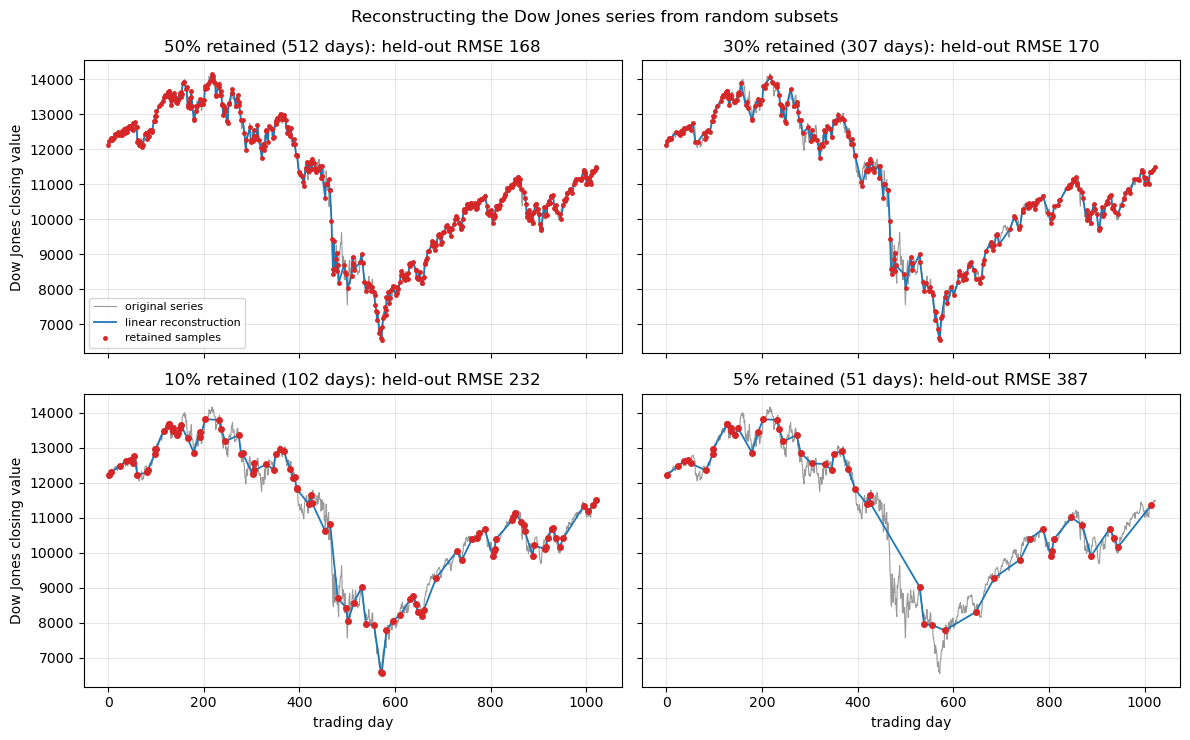

In [7]:
FRACTIONS = (0.50, 0.30, 0.10, 0.05)

rng = np.random.default_rng(SEED)
order = rng.permutation(dow.size)              # one draw, shared by every sampling level


def sample_days(fraction):
    """Sorted indices of the first round(fraction * N) days of the shared permutation."""
    return np.sort(order[:round(fraction*dow.size)])


def reconstruct(idx, kind='linear'):
    """Interpolate dow[idx] onto every day. Days outside [idx[0], idx[-1]] are NaN."""
    f = interpolate.interp1d(idx, dow[idx], kind=kind, bounds_error=False, fill_value=np.nan)
    return f(days)


def heldout_rmse(idx, recon):
    """RMSE over the unsampled days inside the sampled domain."""
    held = np.setdiff1d(np.arange(idx[0], idx[-1] + 1), idx)
    return np.sqrt(np.mean((recon[held] - dow[held])**2))


def random_walk_rmse(idx):
    """Expected linear-interpolation RMSE if the series were a random walk with step std sigma."""
    var = [sigma**2*k*(g - k)/g for g in np.diff(idx) for k in range(1, g)]
    return np.sqrt(np.mean(var))


samples = {f: sample_days(f) for f in FRACTIONS}
recons = {f: reconstruct(idx) for f, idx in samples.items()}

print(f"{'kept':>6s} {'points':>6s} {'edge days lost':>15s} {'mean gap':>9s} {'max gap':>8s} "
      f"{'held-out RMSE':>14s} {'random walk':>12s}")
for f, idx in samples.items():
    gaps = np.diff(idx)
    lost = f"{idx[0]} + {dow.size - 1 - idx[-1]}"
    print(f"{f:6.0%} {idx.size:6d} {lost:>15s} {gaps.mean():9.1f} {gaps.max():8d} "
          f"{heldout_rmse(idx, recons[f]):14.1f} {random_walk_rmse(idx):12.1f}")

# REPORT FIGURE 2: linear reconstructions at the four sampling levels
fig, axs = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, (f, idx) in zip(axs.flat, samples.items()):
    ax.plot(days, dow, color='0.6', lw=0.8, label='original series')
    ax.plot(days, recons[f], color='C0', lw=1.3, label='linear reconstruction')
    ax.plot(idx, dow[idx], 'o', color='C3', ms=2.5 if f > 0.2 else 4, label='retained samples')
    ax.set_title(f'{f:.0%} retained ({idx.size} days): held-out RMSE {heldout_rmse(idx, recons[f]):.0f}')
    ax.grid(alpha=0.3)
for ax in axs[1]:
    ax.set_xlabel('trading day')
for ax in axs[:, 0]:
    ax.set_ylabel('Dow Jones closing value')
axs[0, 0].legend(fontsize=8, loc='lower left')
fig.suptitle('Reconstructing the Dow Jones series from random subsets')
fig.tight_layout()
fig.savefig('interp_dow.png', dpi=150, bbox_inches='tight')

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

**Problem 3 notes**

- The 10% sample from Problem 2 (102 days) is reconstructed with linear, quadratic and cubic
  interpolation, reusing `reconstruct` and `heldout_rmse`.
- Besides the held-out RMSE, the code measures overshoot: how far each curve goes beyond the
  two samples that bracket each gap. A linear interpolant cannot overshoot, so any excursion
  comes from the higher-order terms.
- The right panel zooms in on the window around the steepest fall in the series, where the
  overshoot is largest.

10% sample, 102 days
    method  held-out RMSE  max overshoot  at day
    linear          231.7            0.0       -
 quadratic          342.9          582.3     438
     cubic          354.1          658.8     440


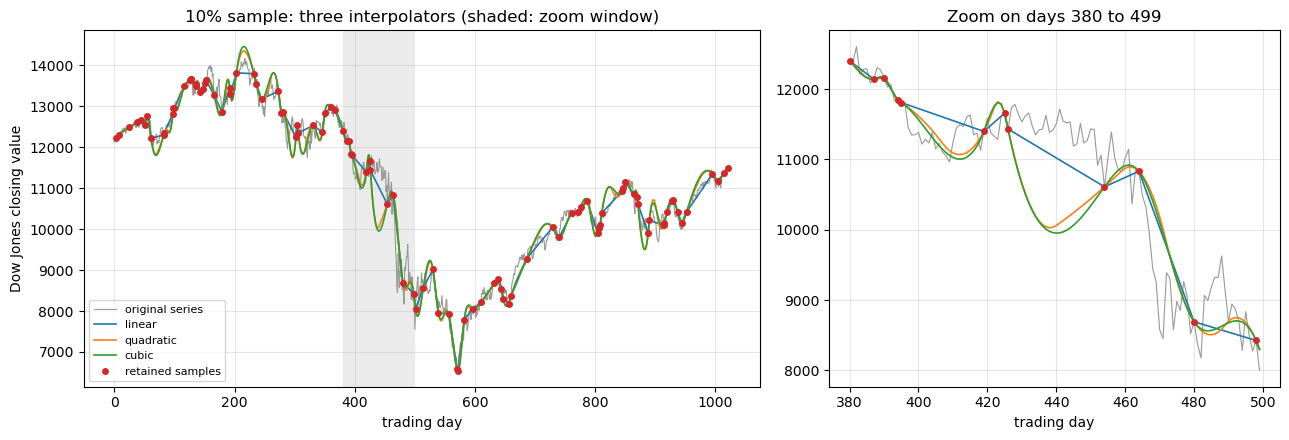

In [8]:
FRACTION_P3 = 0.10
KINDS_P3 = ('linear', 'quadratic', 'cubic')
idx = samples[FRACTION_P3]
recons_p3 = {k: reconstruct(idx, kind=k) for k in KINDS_P3}


def overshoot(idx, recon):
    """Largest distance a reconstruction goes beyond the two samples bracketing a gap, and where."""
    worst, where = 0.0, idx[0]
    for a, b in zip(idx[:-1], idx[1:]):
        if b - a < 2:
            continue
        seg = recon[a + 1:b]
        lo, hi = min(dow[a], dow[b]), max(dow[a], dow[b])
        excess = max(seg.max() - hi, lo - seg.min(), 0.0)
        if excess > worst:
            worst, where = excess, a + 1 + int(np.argmax(np.maximum(seg - hi, lo - seg)))
    return worst, where


print(f"{FRACTION_P3:.0%} sample, {idx.size} days")
print(f"{'method':>10s} {'held-out RMSE':>14s} {'max overshoot':>14s} {'at day':>7s}")
for k, rec in recons_p3.items():
    worst, where = overshoot(idx, rec)
    at_day = f"{where:7d}" if worst > 0 else f"{'-':>7s}"
    print(f"{k:>10s} {heldout_rmse(idx, rec):14.1f} {worst:14.1f} {at_day}")

worst_day = overshoot(idx, recons_p3['cubic'])[1]
window = slice(max(worst_day - 60, 0), min(worst_day + 60, dow.size))
fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [3, 2]})
for ax, sl in ((ax_full, slice(None)), (ax_zoom, window)):
    ax.plot(days[sl], dow[sl], color='0.6', lw=0.8, label='original series')
    for k, color in zip(KINDS_P3, ('C0', 'C1', 'C2')):
        ax.plot(days[sl], recons_p3[k][sl], color=color, lw=1.2, label=k)
    in_view = idx[(idx >= days[sl][0]) & (idx <= days[sl][-1])]
    ax.plot(in_view, dow[in_view], 'o', color='C3', ms=4, label='retained samples')
    ax.set_xlabel('trading day')
    ax.grid(alpha=0.3)
ax_full.axvspan(days[window][0], days[window][-1], color='0.92', zorder=0)
ax_full.set_ylabel('Dow Jones closing value')
ax_full.set_title(f'{FRACTION_P3:.0%} sample: three interpolators (shaded: zoom window)')
ax_zoom.set_title(f'Zoom on days {days[window][0]} to {days[window][-1]}')
ax_full.legend(fontsize=8, loc='lower left')
fig.tight_layout()

### Problem  code summary


Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---

**Code summary**

The script reconstructs a known function and a real time series from random subsets of their
samples, with `scipy.interpolate.interp1d` doing the interpolation and every comparison scored
against the original values. Accuracy is always measured on points the interpolant did not see
(a dense grid for the sine, held-out days for the Dow), and the Dow sampling levels share one
random permutation, so the differences reported come from the method or the amount of data
rather than from chance. Reconstructions are never extended past the sampled domain, and a
random-walk error estimate is computed alongside the measured error so the trends are explained
by a model instead of only described.